In [1]:
import pandas as pd

In [2]:
customers = pd.read_csv(
    r"C:\Users\Pc\Downloads\Ecommerce-Data-Analysis\data\customers.csv")

products = pd.read_csv(
    r"C:\Users\Pc\Downloads\Ecommerce-Data-Analysis\data\products.csv")

orders = pd.read_csv(
    r"C:\Users\Pc\Downloads\Ecommerce-Data-Analysis\data\orders.csv")

In [26]:
# 1.Understand the Data

In [3]:
customers.head()

,customer_id,customer_name,city,state,signup_date
0,C0001,Customer_0001,Chennai,Tamil Nadu,2025-07-07
1,C0002,Customer_0002,Bengaluru,Karnataka,2025-01-08
2,C0003,Customer_0003,Jaipur,Rajasthan,2025-09-28
3,C0004,Customer_0004,Pune,Maharashtra,2024-06-15
4,C0005,Customer_0005,Chennai,Tamil Nadu,2025-04-03


In [4]:
customers.shape

(2000, 5)

In [5]:
customers.columns

Index(['customer_id', 'customer_name', 'city', 'state', 'signup_date'], dtype='str')

In [6]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customer_id    2000 non-null   str  
 1   customer_name  2000 non-null   str  
 2   city           2000 non-null   str  
 3   state          2000 non-null   str  
 4   signup_date    2000 non-null   str  
dtypes: str(5)
memory usage: 78.3 KB


In [7]:
orders.shape

(10000, 7)

In [8]:
orders.columns

Index(['order_id', 'customer_id', 'product_id', 'order_date', 'quantity',
       'status', 'payment_method'],
      dtype='str')

In [9]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   order_id        10000 non-null  str  
 1   customer_id     10000 non-null  str  
 2   product_id      10000 non-null  str  
 3   order_date      10000 non-null  str  
 4   quantity        10000 non-null  int64
 5   status          10000 non-null  str  
 6   payment_method  10000 non-null  str  
dtypes: int64(1), str(6)
memory usage: 547.0 KB


In [11]:
products.shape

(100, 4)

In [13]:
products.columns

Index(['product_id', 'product_name', 'category', 'price'], dtype='str')

In [14]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    100 non-null    str    
 1   product_name  100 non-null    str    
 2   category      100 non-null    str    
 3   price         100 non-null    float64
dtypes: float64(1), str(3)
memory usage: 3.3 KB


In [15]:
# 2.check missing values

In [17]:
customers.isnull().sum()

customer_id      0
customer_name    0
city             0
state            0
signup_date      0
dtype: int64

In [18]:
products.isnull().sum()

product_id      0
product_name    0
category        0
price           0
dtype: int64

In [19]:
orders.isnull().sum()

order_id          0
customer_id       0
product_id        0
order_date        0
quantity          0
status            0
payment_method    0
dtype: int64

In [20]:
# 3.Check Duplicate Records

In [21]:
customers.duplicated().sum()

np.int64(0)

In [22]:
products.duplicated().sum()

np.int64(0)

In [23]:
orders.duplicated().sum()

np.int64(0)

In [27]:
# 4 .Data Type Conversion 

In [28]:
products.dtypes

product_id          str
product_name        str
category            str
price           float64
dtype: object

In [29]:
orders.dtypes

order_id            str
customer_id         str
product_id          str
order_date          str
quantity          int64
status              str
payment_method      str
dtype: object

In [30]:
products.dtypes

product_id          str
product_name        str
category            str
price           float64
dtype: object

In [31]:
# Attention on order_date,

In [32]:
customers["signup_date"] = pd.to_datetime(customers["signup_date"])
orders["order_date"] = pd.to_datetime(orders["order_date"])

In [33]:
customers.dtypes

customer_id                 str
customer_name               str
city                        str
state                       str
signup_date      datetime64[us]
dtype: object

In [34]:
orders.dtypes

order_id                     str
customer_id                  str
product_id                   str
order_date        datetime64[us]
quantity                   int64
status                       str
payment_method               str
dtype: object

In [35]:
# 5. Descriptive Statistics 

In [36]:
orders.describe()

,order_date,quantity
count,10000,10000.000000
mean,2025-06-30 15:08:55.680000,1.926800
min,2025-01-01 00:00:00,1.000000
25%,2025-03-28 00:00:00,1.000000
50%,2025-06-29 00:00:00,2.000000
75%,2025-10-02 00:00:00,2.250000
max,2025-12-31 00:00:00,5.000000
std,NaN,1.064028


In [37]:
products.describe()

,price
count,100.000000
mean,3728.498200
std,4196.842821
min,413.460000
25%,1501.227500
50%,2503.245000
75%,4221.482500
max,26587.790000


In [38]:
products["price"].describe()

count      100.000000
mean      3728.498200
std       4196.842821
min        413.460000
25%       1501.227500
50%       2503.245000
75%       4221.482500
max      26587.790000
Name: price, dtype: float64

In [39]:
orders["quantity"].describe()

count    10000.000000
mean         1.926800
std          1.064028
min          1.000000
25%          1.000000
50%          2.000000
75%          2.250000
max          5.000000
Name: quantity, dtype: float64

In [40]:
# 6. Revenue Analysis

In [41]:
sales = orders.merge(
    products[["product_id", "price"]],
    on="product_id",
    how="left")

In [42]:
sales.head()

,order_id,customer_id,product_id,order_date,quantity,status,payment_method,price
0,O00001,C1309,P091,2025-07-14,1,Delivered,UPI,2807.84
1,O00002,C1263,P052,2025-03-03,2,Delivered,Cash on Delivery,9657.62
2,O00003,C1701,P089,2025-04-17,1,Pending,Cash on Delivery,2030.75
3,O00004,C1623,P024,2025-05-05,1,Delivered,Cash on Delivery,1376.63
4,O00005,C0653,P072,2025-10-28,3,Delivered,UPI,5295.16


In [44]:
#Calculate Revenue
sales["revenue"] = sales["quantity"] * sales["price"]

In [45]:
sales[["order_id", "quantity", "price", "revenue"]].head()

,order_id,quantity,price,revenue
0,O00001,1,2807.84,2807.84
1,O00002,2,9657.62,19315.24
2,O00003,1,2030.75,2030.75
3,O00004,1,1376.63,1376.63
4,O00005,3,5295.16,15885.48


In [46]:
# Calculate Total Revenue
total_revenue = sales["revenue"].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 72067144.37


In [47]:
# 7. Revenue by Category

In [48]:
sales["revenue"]

0        2807.84
1       19315.24
2        2030.75
3        1376.63
4       15885.48
          ...   
9995     2811.20
9996     2809.36
9997     1024.42
9998    24062.49
9999     3233.96
Name: revenue, Length: 10000, dtype: float64

In [49]:
sales = orders.merge(
    products[["product_id", "price", "category"]],
    on="product_id",
    how="left")

In [50]:
sales["revenue"] = sales["quantity"] * sales["price"]

In [51]:
category_revenue = (
    sales.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(category_revenue)

category
Fashion           20503756.90
Beauty            18619954.64
Home & Kitchen    11301647.07
Electronics        9963364.73
Books              6420996.00
Sports             5257425.03
Name: revenue, dtype: float64


In [ ]:
#  8. Top 10 Products by Revenue

In [6]:
# If product_name is NOT in your sales DataFrame
sales = orders.merge(
    products[["product_id", "product_name", "price"]],
    on="product_id",
    how="left"
)

sales["revenue"] = sales["quantity"] * sales["price"]

In [5]:
top_products = (
    sales.groupby(["product_id", "product_name"])["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

product_id  product_name
P077        Product_077     5734166.76
P092        Product_092     4945328.94
P042        Product_042     2878792.22
P053        Product_053     2523406.20
P052        Product_052     2443377.86
P099        Product_099     2124822.00
P048        Product_048     1865559.91
P064        Product_064     1727313.40
P026        Product_026     1539999.36
P078        Product_078     1440123.26
Name: revenue, dtype: float64


In [7]:
# 9. Monthly Revenue

In [10]:
# Create a month column
sales["order_date"].dtype

<StringDtype(storage='python', na_value=nan)>

In [14]:
sales["order_date"] = pd.to_datetime(sales["order_date"])

sales["month"] = sales["order_date"].dt.to_period("M")

monthly_revenue = (
    sales.groupby("month")["revenue"]
    .sum()
    .sort_index()
)

print(monthly_revenue)

month
2025-01    6316601.12
2025-02    6097242.64
2025-03    6552378.33
2025-04    5608396.96
2025-05    6213179.69
2025-06    5474608.48
2025-07    5679519.33
2025-08    6045590.65
2025-09    5389995.88
2025-10    6898504.36
2025-11    5671533.77
2025-12    6119593.16
Freq: M, Name: revenue, dtype: float64


In [15]:
# 10. Monthly Revenue Visualization

In [16]:
import matplotlib.pyplot as plt 

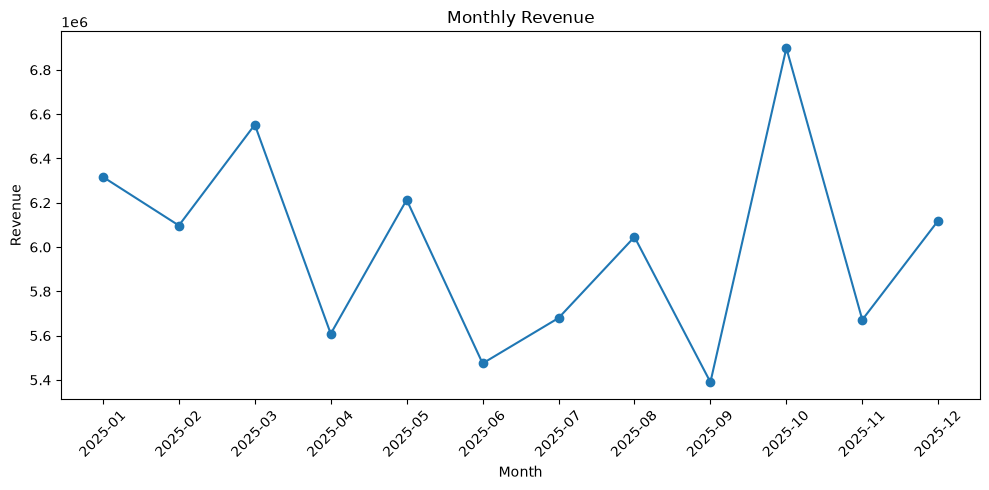

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [18]:
# 11. Revenue by Category Visualization

In [26]:
sales.columns
sales = orders.merge(
    products[["product_id", "product_name", "price", "category"]],
    on="product_id",
    how="left"
)


In [25]:
sales["revenue"] = sales["quantity"] * sales["price"]

category_revenue = (
    sales.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(category_revenue)

category
Fashion           20503756.90
Beauty            18619954.64
Home & Kitchen    11301647.07
Electronics        9963364.73
Books              6420996.00
Sports             5257425.03
Name: revenue, dtype: float64


category
Fashion           20503756.90
Beauty            18619954.64
Home & Kitchen    11301647.07
Electronics        9963364.73
Books              6420996.00
Sports             5257425.03
Name: revenue, dtype: float64


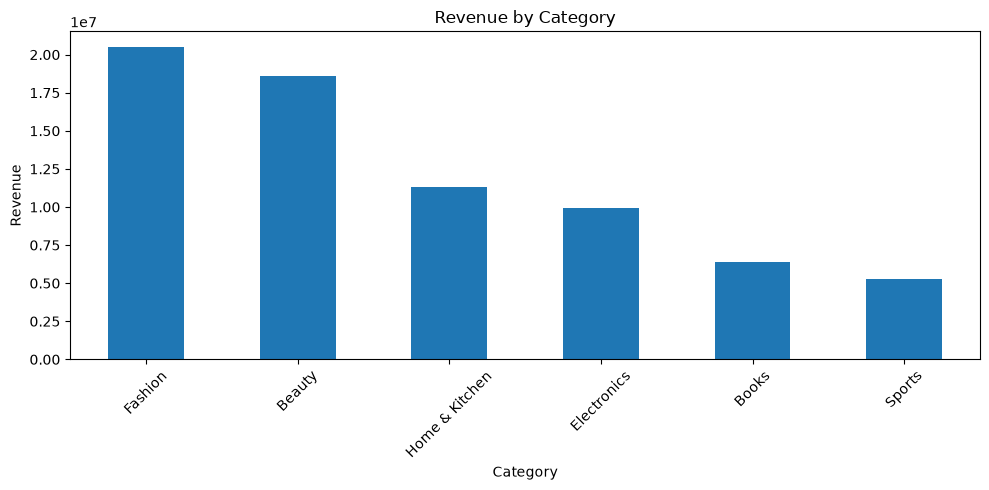

In [28]:
plt.figure(figsize=(10, 5))

category_revenue.plot(kind="bar")

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
# 12.Top 10 Products by Revenue

In [30]:
top_products = (
    sales.groupby("product_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

product_name
Product_077    5734166.76
Product_092    4945328.94
Product_042    2878792.22
Product_053    2523406.20
Product_052    2443377.86
Product_099    2124822.00
Product_048    1865559.91
Product_064    1727313.40
Product_026    1539999.36
Product_078    1440123.26
Name: revenue, dtype: float64


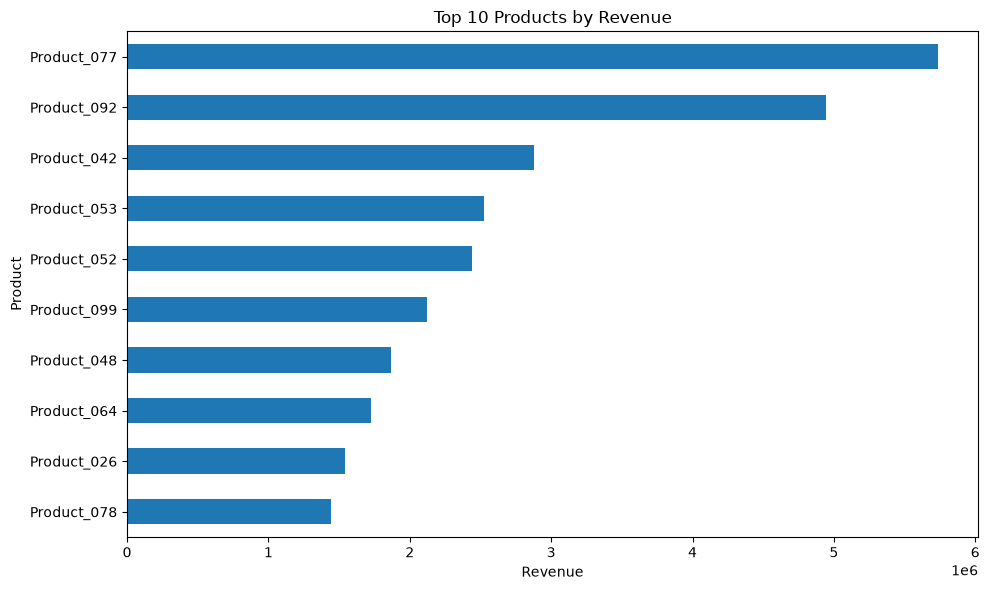

In [31]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [32]:
# 13. Top 10 Customers by Spending

In [33]:
customer_sales = sales.merge(
    customers[["customer_id", "customer_name"]],
    on="customer_id",
    how="left"
)

In [34]:
top_customers = (
    customer_sales.groupby(
        ["customer_id", "customer_name"]
    )["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers)

customer_id  customer_name
C1917        Customer_1917    251911.33
C1469        Customer_1469    184858.37
C0713        Customer_0713    174657.20
C0778        Customer_0778    167553.28
C0038        Customer_0038    165662.35
C1110        Customer_1110    162672.47
C1807        Customer_1807    162281.12
C1888        Customer_1888    153120.47
C0959        Customer_0959    150434.98
C1523        Customer_1523    148101.76
Name: revenue, dtype: float64


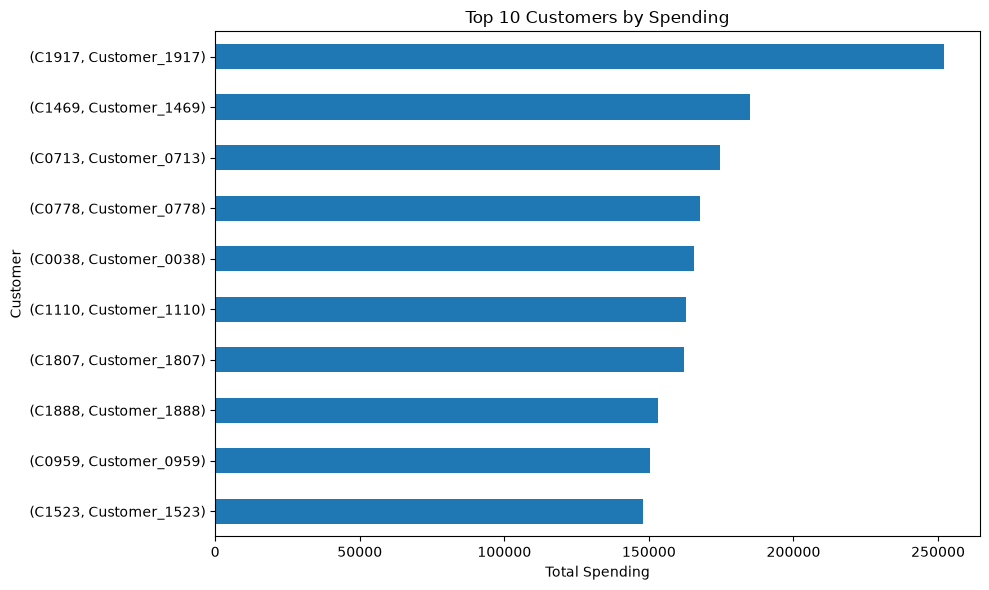

In [35]:
plt.figure(figsize=(10, 6))

top_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer")

plt.tight_layout()
plt.show()

In [36]:
# 14.Repeat Customer Analysis

In [37]:
customer_orders = (
    orders.groupby("customer_id")["order_id"]
    .count()
    .sort_values(ascending=False)
)

print(customer_orders.head(10))

customer_id
C1807    14
C0639    13
C0528    13
C0396    12
C0849    12
C0429    12
C1117    12
C1097    11
C0271    11
C1823    11
Name: order_id, dtype: int64


In [38]:
repeat_customers = customer_orders[customer_orders > 1]

print("Repeat Customers:", len(repeat_customers))

Repeat Customers: 1922


In [39]:
one_time_customers = customer_orders[customer_orders == 1]

print("One-Time Customers:", len(one_time_customers))

One-Time Customers: 63


In [40]:
customer_type = {
    "One-Time Customers": len(one_time_customers),
    "Repeat Customers": len(repeat_customers)
}

print(customer_type)

{'One-Time Customers': 63, 'Repeat Customers': 1922}


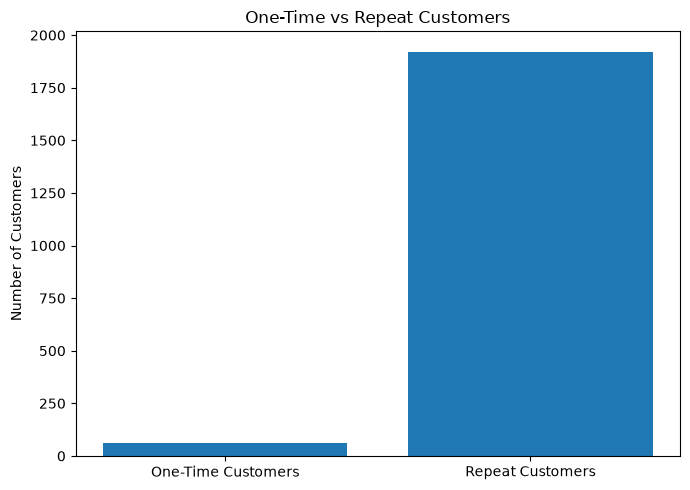

In [41]:
plt.figure(figsize=(7, 5))

plt.bar(
    customer_type.keys(),
    customer_type.values()
)

plt.title("One-Time vs Repeat Customers")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [42]:
# 15.Customer Retention Rate 

In [43]:
repeat_customers = customer_orders[customer_orders > 1]

repeat_count = len(repeat_customers)

print("Repeat Customers:", repeat_count)

Repeat Customers: 1922


In [44]:
total_customers = customers["customer_id"].nunique()

print("Total Customers:", total_customers)

Total Customers: 2000


In [45]:
retention_rate = (repeat_count / total_customers) * 100

print("Customer Retention Rate:", round(retention_rate, 2), "%")

Customer Retention Rate: 96.1 %


In [46]:
# 16 Order Status Analysis

In [47]:
order_status = orders["status"].value_counts()

print(order_status)

status
Delivered    7835
Cancelled     807
Pending       697
Returned      661
Name: count, dtype: int64


In [48]:
order_status_percentage = (
    orders["status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(order_status_percentage)

status
Delivered    78.35
Cancelled     8.07
Pending       6.97
Returned      6.61
Name: proportion, dtype: float64


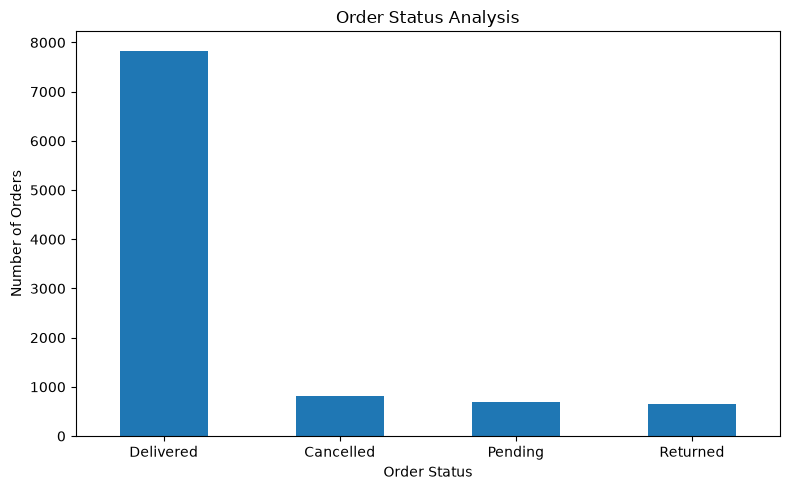

In [49]:
plt.figure(figsize=(8, 5))

order_status.plot(kind="bar")

plt.title("Order Status Analysis")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [51]:
# 17.Cancellation Rate 

In [52]:
cancelled_orders = (orders["status"] == "Cancelled").sum()

print("Cancelled Orders:", cancelled_orders)

Cancelled Orders: 807


In [53]:
total_orders = len(orders)

print("Total Orders:", total_orders)

Total Orders: 10000


In [54]:
cancellation_rate = (cancelled_orders / total_orders) * 100

print("Cancellation Rate:", round(cancellation_rate, 2), "%")

Cancellation Rate: 8.07 %


In [55]:
# 18.Revenue by City 

In [56]:
city_sales = sales.merge(
    customers[["customer_id", "city"]],
    on="customer_id",
    how="left"
)

In [57]:
city_revenue = (
    city_sales.groupby("city")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(city_revenue)

city
Ahmedabad    8539106.49
Pune         8300717.76
Kolkata      8138616.34
Hyderabad    7065423.60
Mumbai       6948599.79
Jaipur       6760801.56
Chennai      6729406.65
Surat        6676979.27
Bengaluru    6676704.21
Delhi        6230788.70
Name: revenue, dtype: float64


In [58]:
top_cities = city_revenue.head(10)

print(top_cities)

city
Ahmedabad    8539106.49
Pune         8300717.76
Kolkata      8138616.34
Hyderabad    7065423.60
Mumbai       6948599.79
Jaipur       6760801.56
Chennai      6729406.65
Surat        6676979.27
Bengaluru    6676704.21
Delhi        6230788.70
Name: revenue, dtype: float64


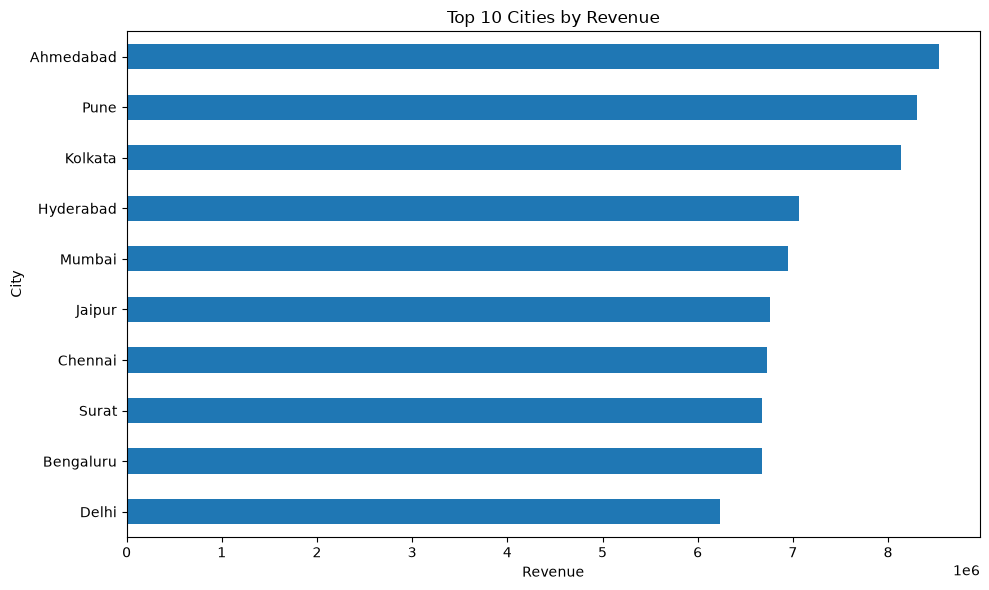

In [59]:
plt.figure(figsize=(10, 6))

top_cities.sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Revenue")
plt.xlabel("Revenue")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [60]:
# 19. Revenue by Payment Method 

In [61]:
payment_revenue = (
    sales.groupby("payment_method")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(payment_revenue)

payment_method
UPI                 27567038.45
Credit Card         17641500.42
Debit Card          12866161.31
Cash on Delivery    10195772.63
Net Banking          3796671.56
Name: revenue, dtype: float64


In [62]:
payment_percentage = (
    payment_revenue / payment_revenue.sum() * 100
).round(2)

print(payment_percentage)

payment_method
UPI                 38.25
Credit Card         24.48
Debit Card          17.85
Cash on Delivery    14.15
Net Banking          5.27
Name: revenue, dtype: float64


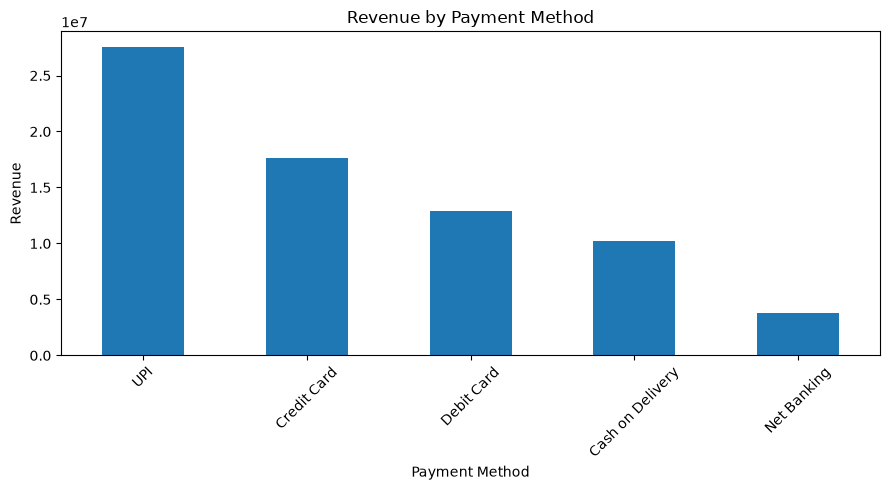

In [63]:
plt.figure(figsize=(9, 5))

payment_revenue.plot(kind="bar")

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [64]:
# 20.Overall Sales Performance Summary

In [65]:
total_revenue = sales["revenue"].sum()
total_orders = orders["order_id"].nunique()
total_customers = customers["customer_id"].nunique()
total_units = orders["quantity"].sum()
average_order_value = total_revenue / total_orders

In [66]:
print("===== E-COMMERCE SALES SUMMARY =====")
print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Units Sold:", total_units)
print("Average Order Value:", round(average_order_value, 2))
print("Cancellation Rate:", round(cancellation_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")

===== E-COMMERCE SALES SUMMARY =====
Total Revenue: 72067144.37
Total Orders: 10000
Total Customers: 2000
Total Units Sold: 19268
Average Order Value: 7206.71
Cancellation Rate: 8.07 %
Retention Rate: 96.1 %
